# Predictive Customer Churn Classifier — Random Forest & XGBoost
**Goal:** predict telecom customer churn, handle class imbalance, and reach **ROC-AUC > 0.80**.

**Pipeline:** load → clean `TotalCharges` → `OneHotEncoder` (+ scaling) → **SMOTE / class weighting** → Random Forest & XGBoost → stratified CV → ROC curves, confusion matrix, top-10 feature importances.

> **Leakage note:** SMOTE is placed *inside* an `imblearn` Pipeline, so synthetic samples are generated only from the training folds during cross-validation. Oversampling before splitting would inflate the scores.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
RS = 42

## 1. Load data & clean `TotalCharges`
The 11 blank `TotalCharges` values belong to customers with `tenure == 0` (brand-new, not yet billed), so they are set to **0** rather than dropped.

In [2]:
import os
PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # put your CSV next to the notebook
URL  = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(PATH if os.path.exists(PATH) else URL)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Null TotalCharges:", df["TotalCharges"].isna().sum(), "| all have tenure==0:", (df.loc[df.TotalCharges.isna(), "tenure"] == 0).all())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["customerID", "Churn"])
print(df.shape); print("Churn rate: %.1f%%  (imbalance ratio %.2f : 1)" % (100*y.mean(), (1-y.mean())/y.mean()))

Null TotalCharges: 11 | all have tenure==0: True
(7043, 21)
Churn rate: 26.5%  (imbalance ratio 2.77 : 1)


In [3]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
neg_pos = (y_train == 0).sum() / (y_train == 1).sum()
print("Train", X_train.shape, "Test", X_test.shape, "| scale_pos_weight =", round(neg_pos, 2))

Train (5634, 19) Test (1409, 19) | scale_pos_weight = 2.77


## 2. Models
Three imbalance strategies are compared so the choice is evidence-based:
* **RF + SMOTE** — Random Forest on SMOTE-oversampled training folds
* **RF + class_weight** — no resampling, `class_weight="balanced_subsample"`
* **XGB + scale_pos_weight** — XGBoost with the negative/positive ratio as the weight

In [4]:
def make(model, smote):
    steps = [("pre", pre)]
    if smote: steps.append(("smote", SMOTE(random_state=RS)))
    steps.append(("clf", model))
    return Pipeline(steps)

models = {
  "RF + SMOTE": make(RandomForestClassifier(n_estimators=400, max_depth=10, min_samples_leaf=5, n_jobs=-1, random_state=RS), smote=True),
  "RF + class_weight": make(RandomForestClassifier(n_estimators=400, max_depth=10, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RS), smote=False),
  "XGB + scale_pos_weight": make(XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 scale_pos_weight=neg_pos, eval_metric="auc", n_jobs=-1, random_state=RS), smote=False),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
rows, fitted = [], {}
for name, pipe in models.items():
    cvs = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    pipe.fit(X_train, y_train); fitted[name] = pipe
    rows.append({"model": name, "CV ROC-AUC (mean)": cvs.mean(), "CV std": cvs.std(),
                 "Test ROC-AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])})
results = pd.DataFrame(rows).set_index("model").round(4)
results["> 0.80 ?"] = results["Test ROC-AUC"] > 0.80
results

,CV ROC-AUC (mean),CV std,Test ROC-AUC,> 0.80 ?
model,,,,
RF + SMOTE,0.8429,0.0082,0.8385,True
RF + class_weight,0.8470,0.0087,0.8421,True
XGB + scale_pos_weight,0.8469,0.0113,0.8464,True


## 3. ROC curves (hold-out test set)

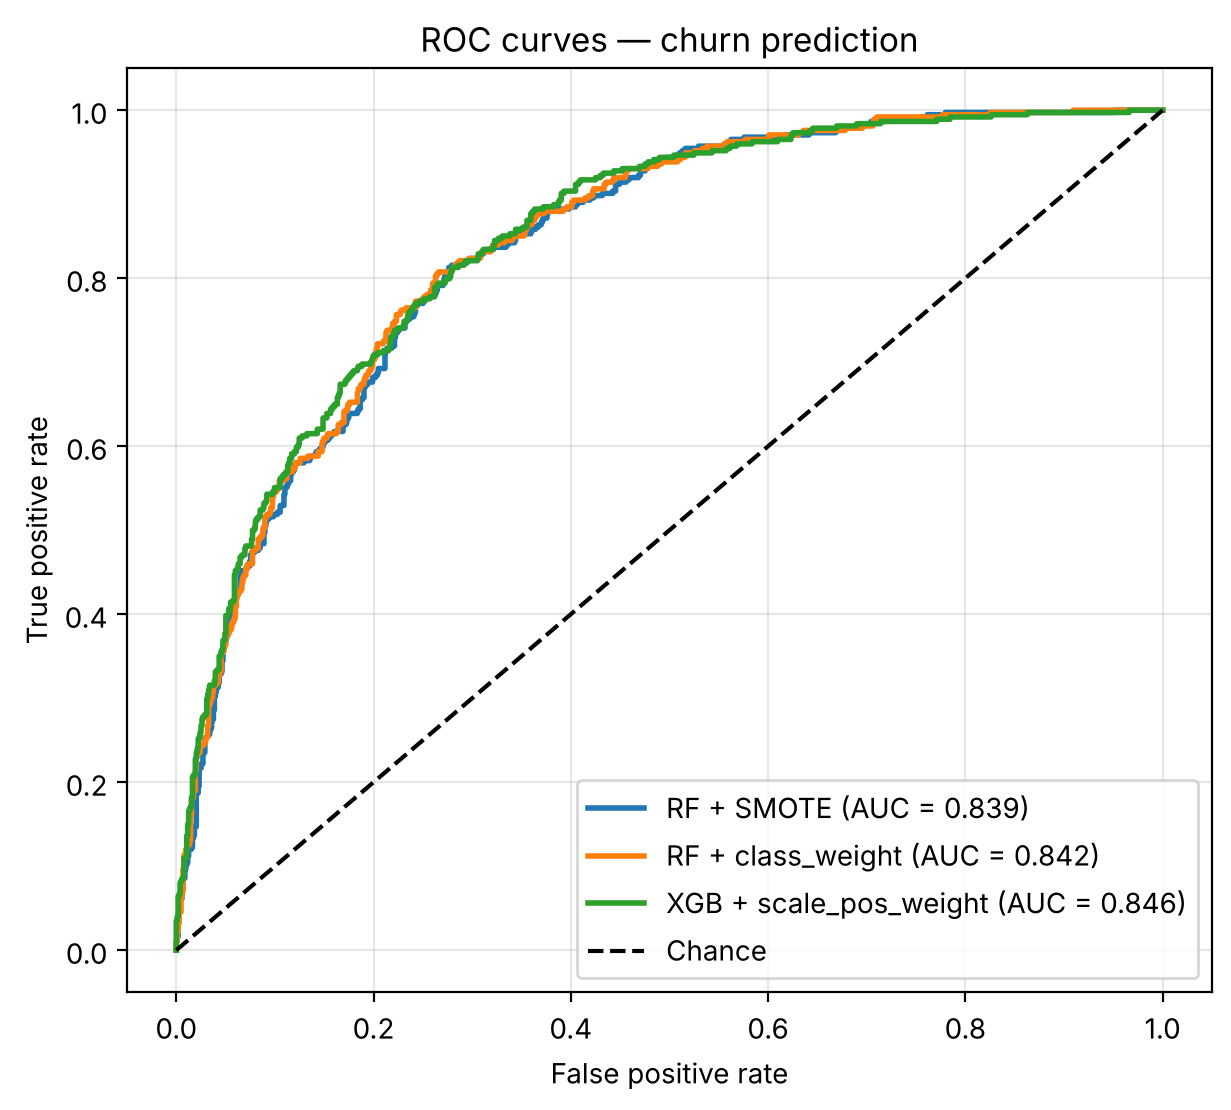

In [5]:
plt.figure(figsize=(7, 6))
for name, pipe in fitted.items():
    p = pipe.predict_proba(X_test)[:, 1]; fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance"); plt.axhline(0, alpha=0)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves — churn prediction")
plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

## 4. Confusion matrices
At the default 0.5 threshold, balanced models trade precision for **recall on churners** — usually what a retention team wants (missing a churner costs more than a wasted discount).

Best model by test ROC-AUC: XGB + scale_pos_weight


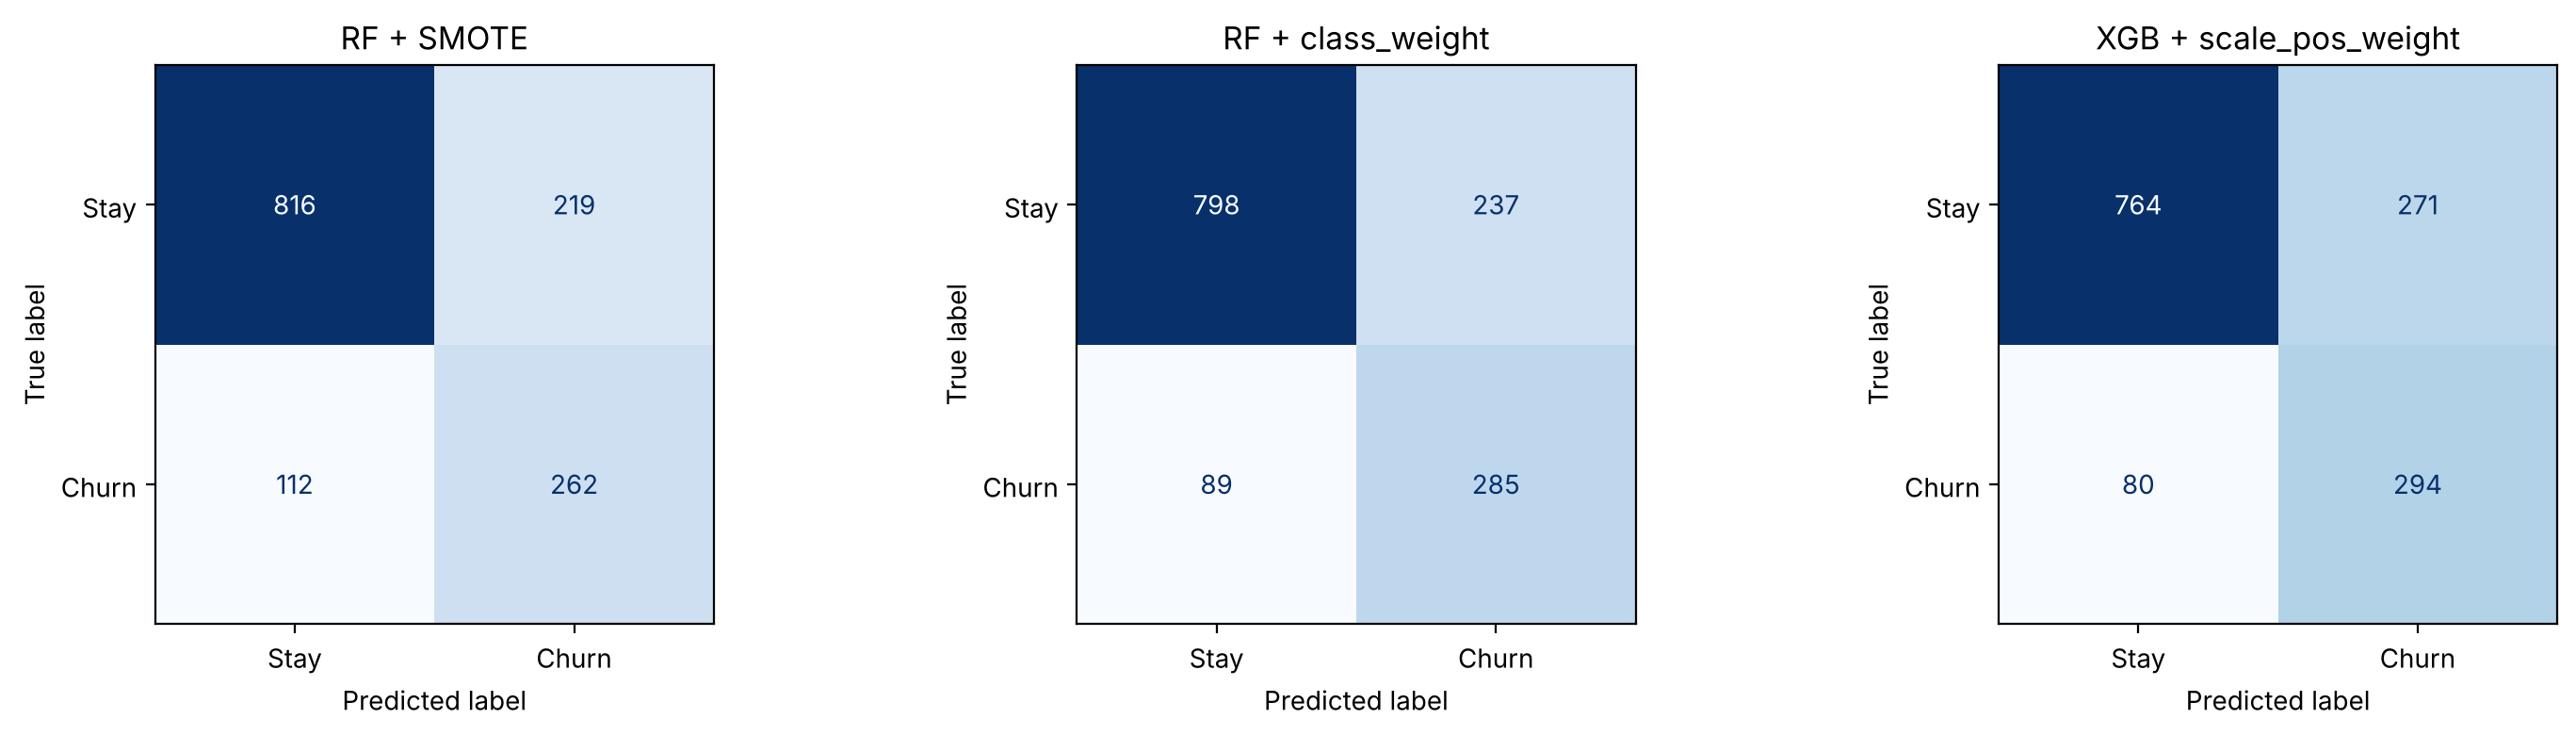

              precision    recall  f1-score   support

        Stay       0.91      0.74      0.81      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [6]:
best = results["Test ROC-AUC"].idxmax(); print("Best model by test ROC-AUC:", best)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)), display_labels=["Stay", "Churn"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()
print(classification_report(y_test, fitted[best].predict(X_test), target_names=["Stay", "Churn"]))

## 5. Top-10 feature importances

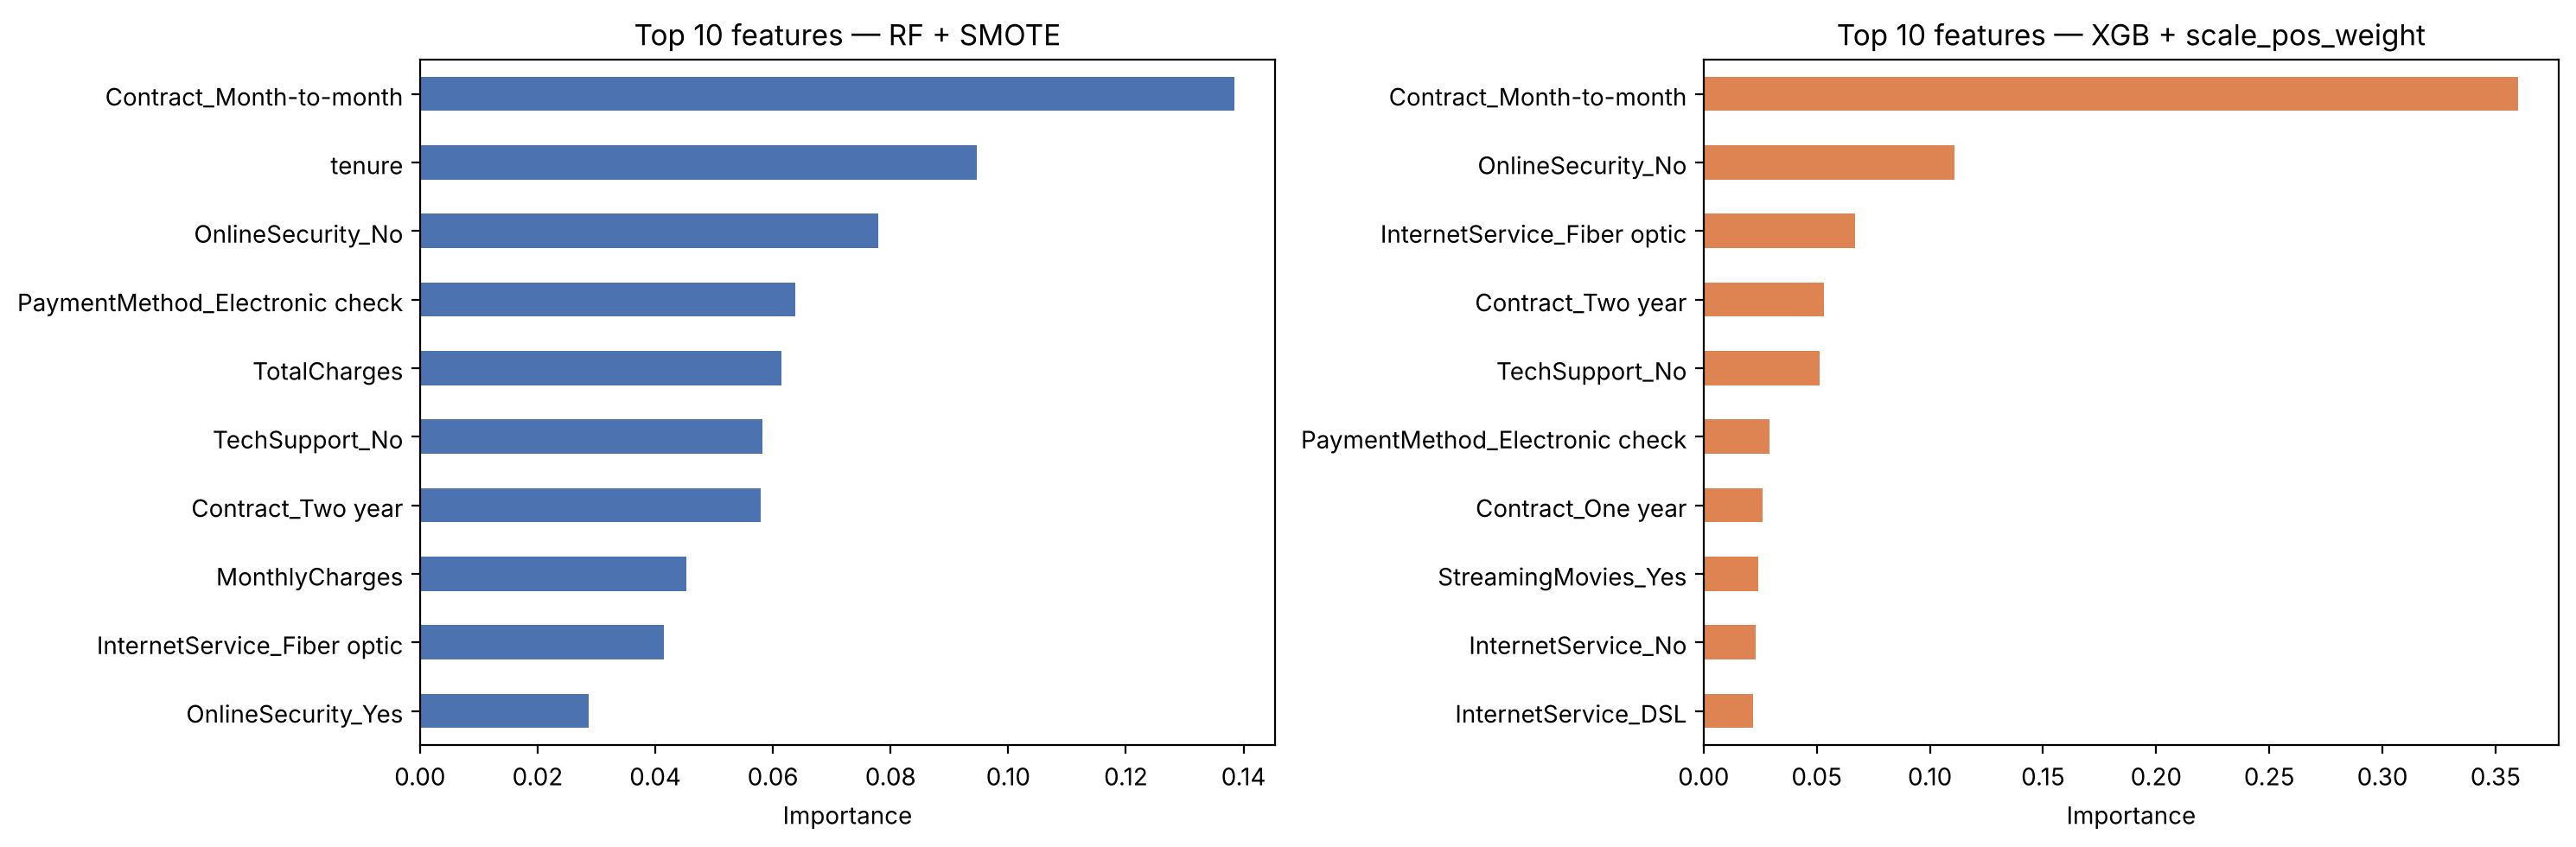

In [7]:
def top10(pipe):
    names = pipe.named_steps["pre"].get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names)
    return imp.sort_values(ascending=False).head(10)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name, color in zip(axes, ["RF + SMOTE", "XGB + scale_pos_weight"], ["#4C72B0", "#DD8452"]):
    top10(fitted[name]).plot.barh(ax=ax, color=color); ax.set_title(f"Top 10 features — {name}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 6. Takeaways
* All three strategies clear the **ROC-AUC > 0.80** target; see the table in section 2 for exact numbers from your run.
* Contract type, tenure, and internet service/fiber/payment method typically dominate: **short-tenure, month-to-month, fiber-optic customers paying by electronic check** are the highest churn risk.
* Impurity-based importances are biased toward high-cardinality/continuous features; for a deeper view use `permutation_importance` or SHAP.
* Next steps: tune the decision threshold to a business cost (retention offer cost vs. customer lifetime value), `RandomizedSearchCV` on XGBoost, calibrate probabilities.